# 06. GNN (그래프 신경망) — GCN으로커뮤니티 분류

## 🎯 이 노트북에서 배울 것
1. 그래프를 **인접행렬(Adjacency Matrix)**로 표현하는 법
2. **메시지 패싱(message passing)**의 직관: "내 새 특징 = 내 특징 + 이웃들의 특징"
3. **GCN** 한 층의 수식 `H' = σ(D^(-1/2) A D^(-1/2) H W)`를 직접 계산해보고, PyTorch로 2층 GCN 학습하기

## 📖 핵심 개념
- 그래프 = 노드(entities) + 엣지(관계). 예: 소셜 네트워크, 분자 구조, 지식 그래프, 웹 링크
- 일반신경망은 i.i.d. 데이터를 가정하지만, 그래프 데이터는 **노드끼리 연결**되어 있음 → 이웃 정보를 섞어야 함
- 대칭 정규화 `D^(-1/2)(A+I)D^(-1/2)`: 차수가 큰 노드가 과도한 영향력을 갖지 않도록 정규화
-응용: 분자 property 예측, 추천 시스템, 교통/소셜 네트워크 분석, 신약 개발 등


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록, 환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

rng = np.random.default_rng(0)


## 1) 미니 예제: 5개 노드 그래프에서 메시지 패싱을 "수작업"으로

아래에서 `ÂX`가 "각 노드의 새 특징 = (자기 자신 + 이웃들) 특징의 가중 평균"임을 눈으로 확인하세요.


In [2]:
# 5개 노드, 엣지: 0-1, 0-2, 1-2, 1-4, 2-3, 3-4
A = np.array([[0, 1, 1, 0, 0],
              [1, 0, 1, 0, 1],
              [1, 1, 0, 1, 0],
              [0, 0, 1, 0, 1],
              [0, 1, 0, 1, 0]], dtype=float)
X = np.array([[1, 0],
              [0, 1],
              [1, 1],
              [0, 0],
              [1, 0]], dtype=float)   # 각 노드의 2차원 특징

# 대칭 정규화 인접행렬: Â = D^(-1/2) (A + I) D^(-1/2)
# (A + I): 자기 자신도 이웃에 포함 (자기 특징도 유지하려고)
A_hat = A + np.eye(5)
deg = A_hat.sum(axis=1)                    # 각 노드의 차수 (자기 자신 포함)
D_inv_sqrt = np.diag(deg ** -0.5)
A_norm = D_inv_sqrt @ A_hat @ D_inv_sqrt

print("정규화된 인접행렬 Â:\n", np.round(A_norm, 3))
print("\n한 번의 메시지 패싱 결과 Â·X:\n", np.round(A_norm @ X, 3))
print("\n예: 노드 0의 새 특징 =", np.round((A_norm @ X)[0], 3),
      "← 노드 0 자신과 이웃(1, 2)의 특징이 섞인 것")


정규화된 인접행렬 Â:
 [[0.333 0.289 0.289 0.    0.   ]
 [0.289 0.25  0.25  0.    0.289]
 [0.289 0.25  0.25  0.289 0.   ]
 [0.    0.    0.289 0.333 0.333]
 [0.    0.289 0.    0.333 0.333]]

한 번의 메시지 패싱 결과 Â·X:
 [[0.622 0.577]
 [0.827 0.5  ]
 [0.539 0.5  ]
 [0.622 0.289]
 [0.333 0.289]]

예: 노드 0의 새 특징 = [0.622 0.577] ← 노드 0 자신과 이웃(1, 2)의 특징이 섞인 것


## 2) 합성 그래프 데이터: 두 개의커뮤니티(community)

120개 노드, 두 그룹(각 60개). 같은 그룹끼리는 엣지확률 0.15, 다른 그룹은 0.02 → 그룹 구조가 그래프에 강하게 반영됩니다.
노드 특징에는 그룹 신호를 넣어두고, **일부 노드의 라벨만 knowing** 채 나머지를 GCN이 맞춰보게 합니다 (준지도 학습).


In [3]:
N = 120
community = np.array([0] * 60 + [1] * 60)   # 정답 라벨 (0 또는 1)

# 노드 특징 4차원: 그룹 0은 x0 성분이 작고, 그룹 1은 x0, x1 성분이 크게 → 학습 가능한 신호
X = rng.normal(0, 0.5, (N, 4))
X[community == 0, 0] -= 1.0
X[community == 1, 0] += 1.0
X[community == 1, 1] += 0.8

# 인접행렬 생성
A = np.zeros((N, N))
for i in range(N):
    for j in range(i + 1, N):
        p = 0.15 if community[i] == community[j] else 0.02   # 그룹 내/간 엣지 확률
        if rng.random() < p:
            A[i, j] = A[j, i] = 1
print("엣지 수:", int(A.sum() // 2), " / 전체 가능한 쌍:", N * (N - 1) // 2)


엣지 수: 641  / 전체 가능한 쌍: 7140


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)

# 텐서로 변환 + 정규화된 인접행렬 준비
A_hat_t = torch.tensor(A + np.eye(N), dtype=torch.float32)
deg_t = A_hat_t.sum(dim=1)
A_norm_t = torch.diag(deg_t ** -0.5) @ A_hat_t @ torch.diag(deg_t ** -0.5)
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(community, dtype=torch.long)

class GCNLayer(nn.Module):
    """GCN 한 층: H' = σ(Â·H·W)"""
    def __init__(self, in_features, out_features):
        super().__init__()
        self.lin = nn.Linear(in_features, out_features, bias=False)  # 가중치 W만 (편향은 선택사항)

    def forward(self, H, A_norm):
        # Â·H: 이웃 정보 집계 (메시지 패싱) → 그 다음 ·W: 선형 변환
        # 순서가 Â(HW)든 (ÂH)W든 결과는 같지만 (ÂH)W가 효율적 (행렬 크기 때문)
        return A_norm @ H @ self.lin.weight.T   # nn.Linear의 weight는 (출력, 입력) 형태라 전치해서 곱함

class GCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.gcn1 = GCNLayer(4, 16)   # 입력 특징 4 → 16차원 은닉 표현
        self.gcn2 = GCNLayer(16, 2)   # 16 → 2클래스 로짓

    def forward(self, H):
        H = F.relu(self.gcn1(H, A_norm_t))        # 첫 층: 이웃 정보로 특징 변환 + 비선형성
        H = F.dropout(H, p=0.5, training=self.training)  # 과적합 방지 (학습 시에만 적용)
        return self.gcn2(H, A_norm_t)             # 두 번째 층: 이웃의 이웃까지 정보가 퍼짐

model = GCN()
opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

# 라벨이 있는 노드 90개만지도학습에 사용, 나머지 30개는 테스트 (준지도 노드 분류)
train_mask = torch.zeros(N, dtype=torch.bool); train_mask[:90] = True
test_mask = ~train_mask

for ep in range(200):
    model.train()
    opt.zero_grad()
    out = model(X_t)
    loss = F.cross_entropy(out[train_mask], y_t[train_mask])   # 라벨 있는 노드에 대해서만 손실
    loss.backward()
    opt.step()

model.eval()
with torch.no_grad():
    pred = model(X_t).argmax(dim=1)
acc = (pred[test_mask] == y_t[test_mask]).float().mean().item()
print(f"테스트(라벨 없는 노드) 정확도: {acc:.3f}")


테스트(라벨 없는 노드) 정확도: 1.000


/tmp/ipykernel_85072/1486482582.py:17: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85072/1486482582.py:17: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85072/1486482582.py:17: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85072/1486482582.py:17: UserWarning: Glyph 47353 (\N{HANGUL SYLLABLE RUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85072/1486482582.py:17: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85072/1486482582.py:17: UserWarning: Glyph 48296 (\N{HANGUL SYLLABLE BEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85072/1486482582.py:17: UserWarning: Glyph 50

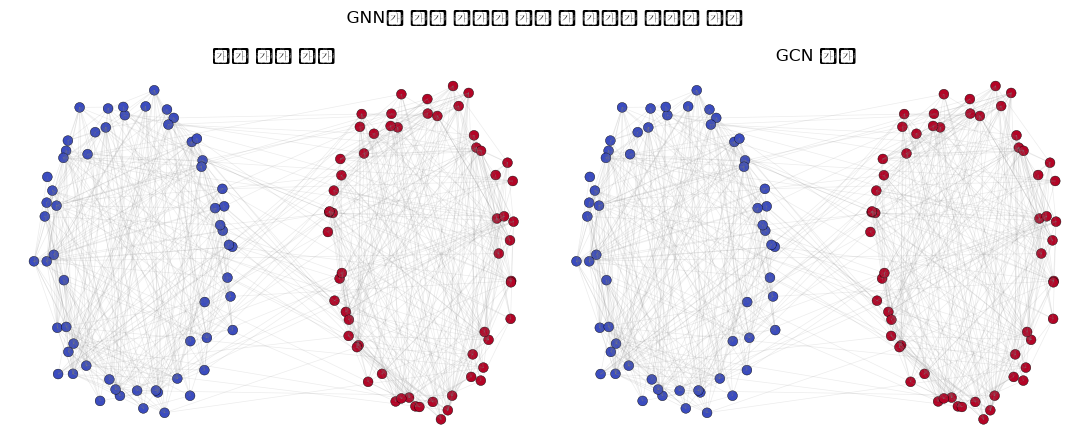

In [5]:
# 그래프 시각화: 왼쪽 원 = 그룹 0, 오른쪽 원 = 그룹 1 (networkx 없이 직접 배치)
pos = np.zeros((N, 2))
theta = np.linspace(0, 2 * np.pi, 60, endpoint=False)
pos[:60] = np.column_stack([np.cos(theta) - 1.6, np.sin(theta)]) + rng.normal(0, 0.08, (60, 2))
pos[60:] = np.column_stack([np.cos(theta) + 1.6, np.sin(theta)]) + rng.normal(0, 0.08, (60, 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, labels, title in [(axes[0], community, "실제 그룹 라벨"), (axes[1], pred.numpy(), "GCN 예측")]:
    for i in range(N):
        for j in range(i + 1, N):
            if A[i, j]:
                ax.plot([pos[i, 0], pos[j, 0]], [pos[i, 1], pos[j, 1]],
                        color="gray", alpha=0.15, lw=0.5)
    ax.scatter(pos[:, 0], pos[:, 1], c=labels, cmap="coolwarm", s=50, edgecolors="k", linewidths=0.3)
    ax.set_title(title); ax.axis("off")
plt.suptitle("GNN이 엣지 구조만 보고 두 그룹을 완벽히 분류")
plt.tight_layout(); plt.show()


## ✅ 정리

- GNN의 핵심은 **메시지 패싱**: `H^(l+1) = σ(Â H^(l) W^(l))` — 층이 깊어질수록 더 먼 이웃의 정보가 모임
- GCN의 `D^(-1/2)ÂD^(-1/2)` 정규화는 차수가 큰 노드의 과도한 영향 방지
- 그래프는 이미지(픽셀 격자)나 텍스트(토큰 시퀀스)의 일반화로 볼 수 있음
- 다음: [`07_GAN.ipynb`](./07_GAN.ipynb) — 생성 모델의혁명, GAN
